# 7. Using the models proactively

* **Recommend** a standard grade and a cooling route for a property specification, using the *lower*
  90 % bound so the recommendation is robust.
* **Map the strength-ductility trade-off** that standard grades can deliver, furnace vs air cooling (only real
  grades are searched; no composition is invented).
* **Plan experiments**: show that adding the most uncertain grade first learns faster than random, that a
  few local measurements recalibrate the model to a new product, and produce a pre-registered prediction
  sheet for the laboratory.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3g}")
R = ROOT / "results"; FIG = ROOT / "figures"
def fig(name, width=1000):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

In [2]:
r = pd.read_csv(R / "s07_recommendations.csv")
r[["spec", "grade", "option", "UTS_MPa_lo90", "YS_MPa_lo90", "El_pct_lo90", "CE_IIW"]]

,spec,grade,option,UTS_MPa_lo90,YS_MPa_lo90,El_pct_lo90,CE_IIW
0,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 1020,"air cooled, 10 mm",410,305,32.4,0.324
1,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 1018,"air cooled, 10 mm",426,305,31.8,0.344
2,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 1023,"air cooled, 10 mm",418,307,31.7,0.344
3,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 1019,"air cooled, 10 mm",436,304,31.4,0.36
4,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 1025,"air cooled, 10 mm",428,309,30.7,0.369
5,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 1021,"air cooled, 10 mm",448,313,31.1,0.374
6,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 1022,"air cooled, 10 mm",458,310,30.5,0.39
7,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 15B21H,"air cooled, 10 mm",465,303,29.7,0.407
8,UTS >= 750 MPa and El >= 18 % without quench-a...,AISI 1335H,"air cooled, 25 mm",760,473,18.8,0.685
9,UTS >= 750 MPa and El >= 18 % without quench-a...,AISI 1340H,"air cooled, 50 mm",789,500,19,0.74


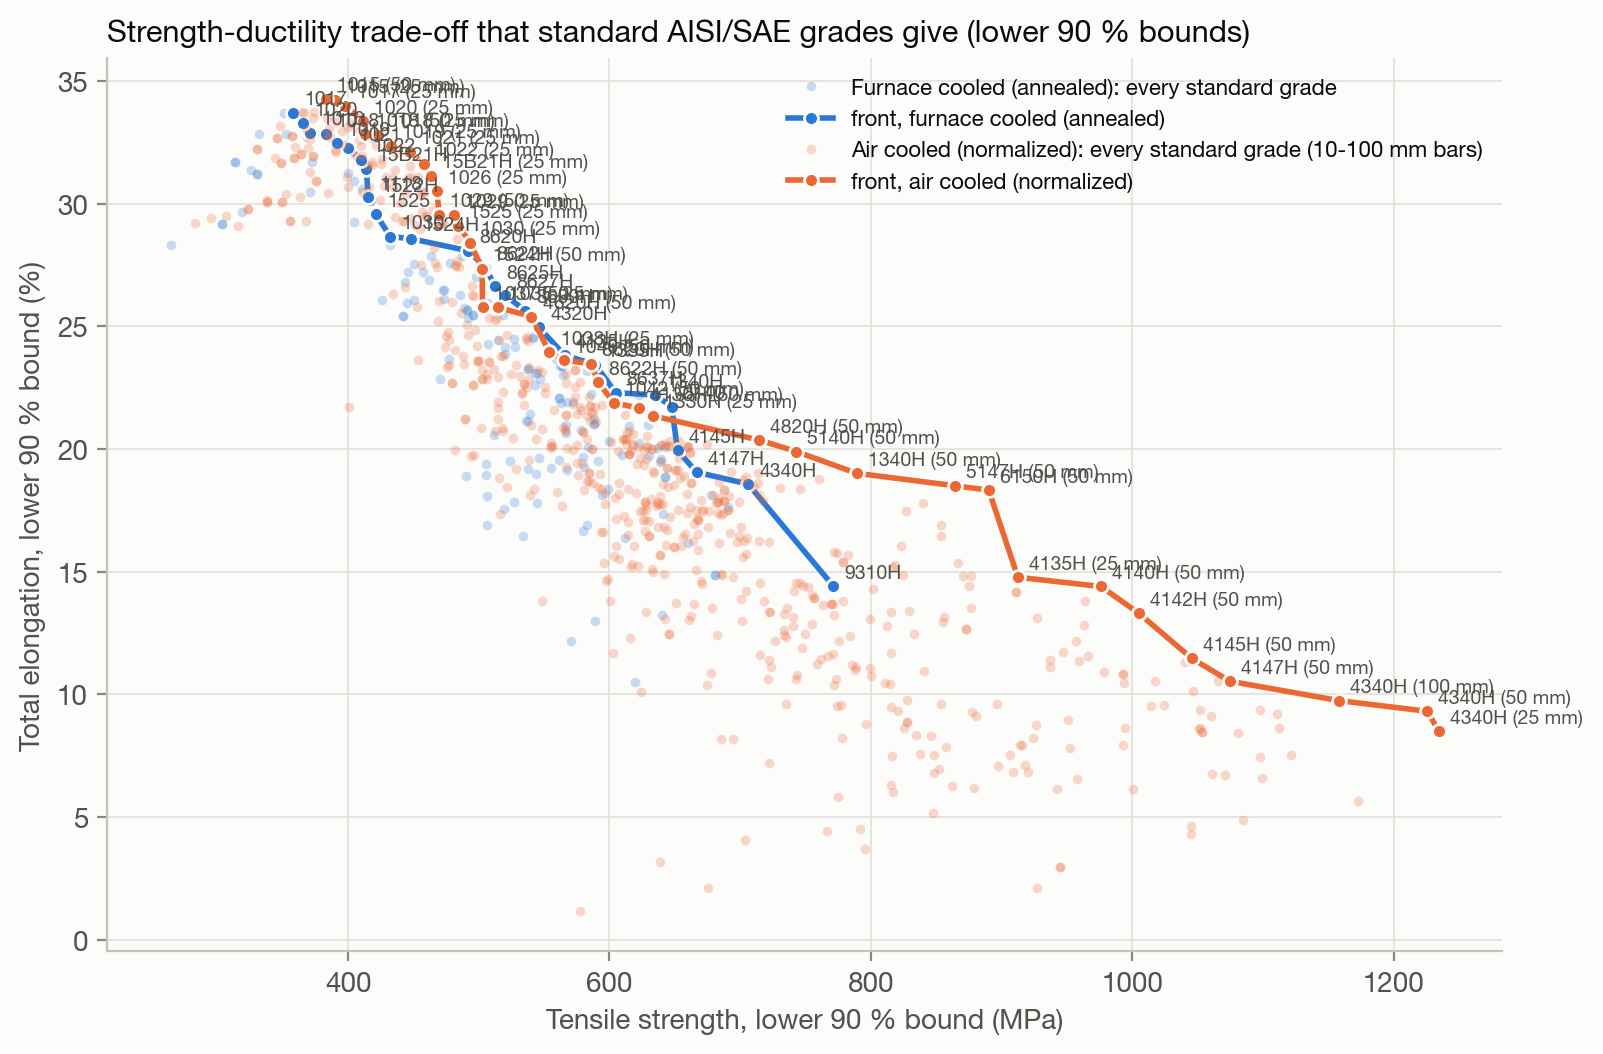

In [3]:
fig("fig22_grade_front_fc_vs_ac", 800)

In [4]:
al = pd.read_csv(R / "s07_active_learning.csv")
al.groupby(["n_grades", "strategy"]).RMSE.mean().unstack().round(1)

strategy,random,uncertainty
n_grades,,
8,109,109
9,110,95.7
10,109,88.1
11,104,85.5
12,103,68.7
13,92.7,71.6
14,94.1,69.2
15,95,67.8
16,92,68


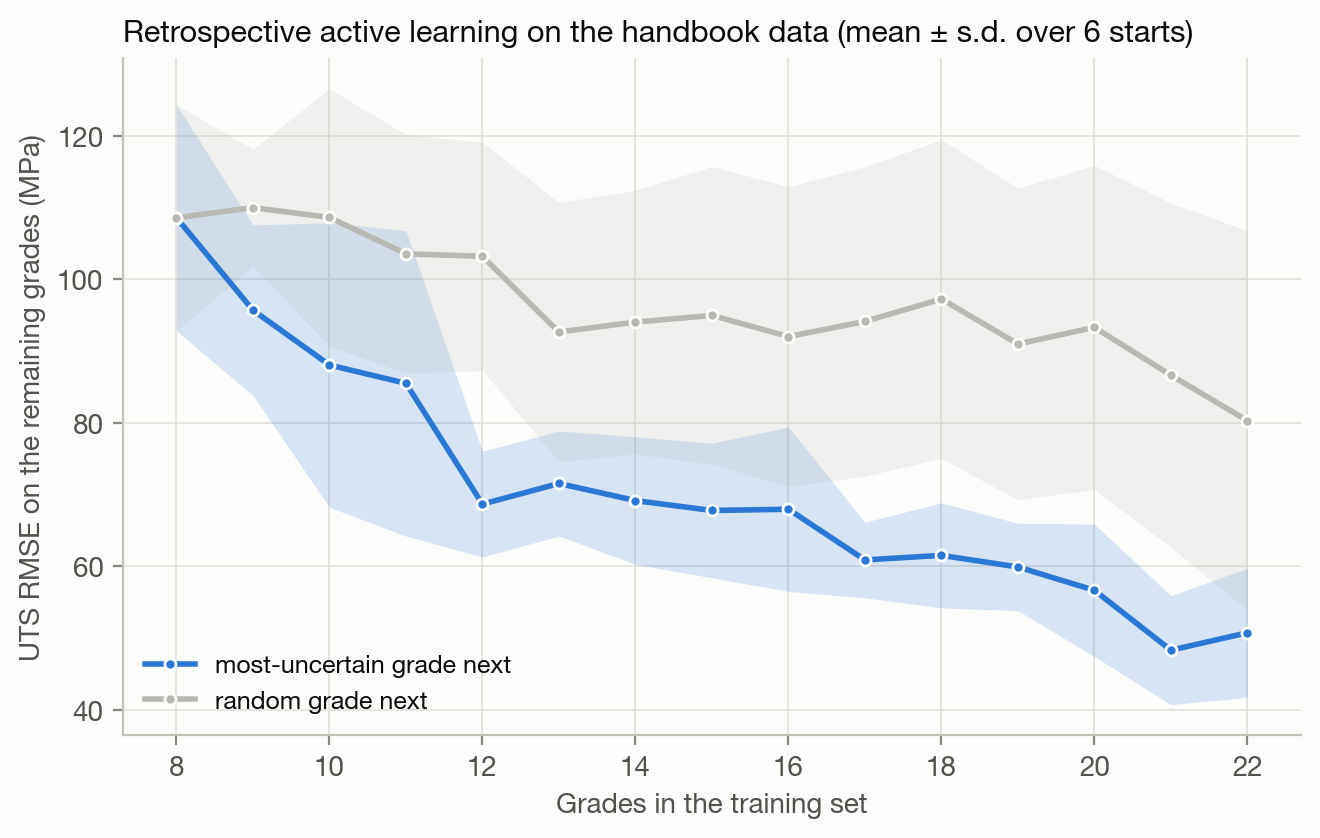

In [5]:
fig("fig23_active_learning", 750)

In [6]:
pd.read_csv(R / "s07_few_shot.csv").groupby(["target", "k_added"])[["RMSE", "bias"]].mean().round(1)

RMSE  bias
target  k_added            
UTS_MPa 0        54.7 -41.3
        5        32.9  -9.7
        10       27.3  -3.2
        20       25.1  -4.4
        40       24.2  -2.3
YS_MPa  0        81.3 -57.7
        5        55.8 -23.2
        10       46.2 -15.5
        20       39.5  -6.1
        40       36.8  -4.8

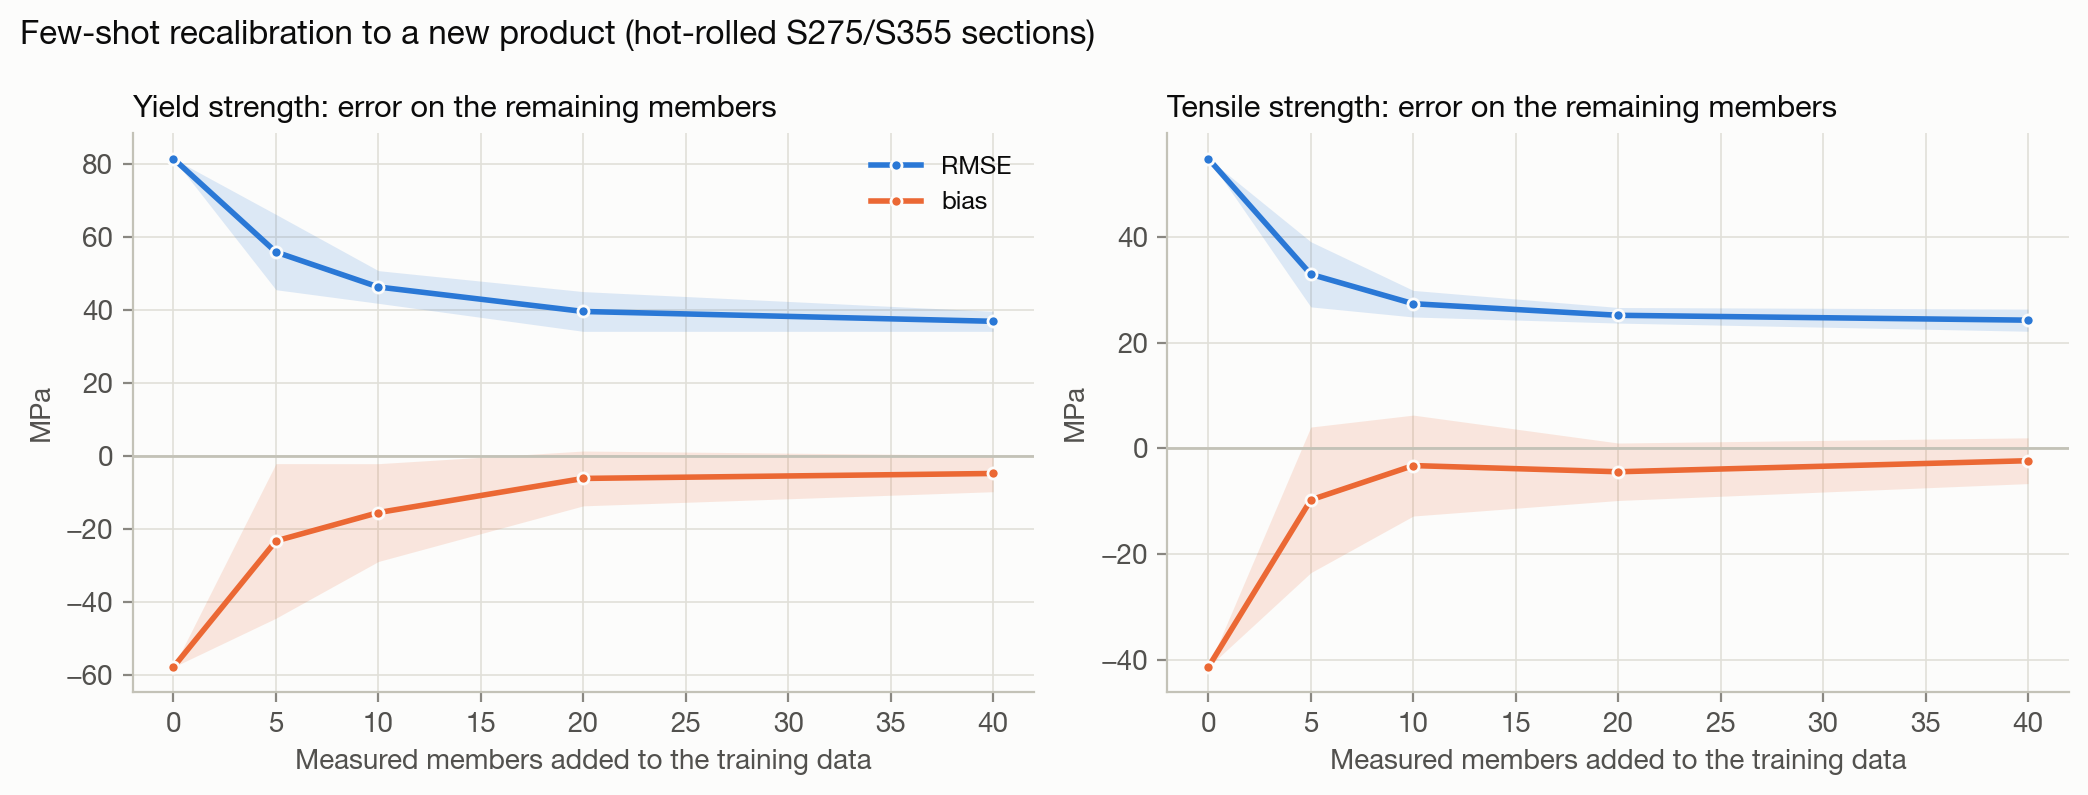

In [7]:
fig("fig24_few_shot_recalibration", 900)

## Pre-registered laboratory plan
Predictions are fixed *before* the experiments, so the lab results are a genuine test. Steels commonly
stocked in Indian laboratories are listed with their AISI equivalents, ranked by expected information
(width of the prediction intervals).

In [8]:
pd.read_csv(R / "s07_lab_plan_preregistered.csv")

,steel,option,austenitise_C,ferrite_frac,pearlite_frac,bainite_frac,martensite_frac,pearlite_spacing_nm,YS_MPa_pred,YS_MPa_90PI,UTS_MPa_pred,UTS_MPa_90PI,El_pct_pred,El_pct_90PI,HB_pred,HB_90PI,uniform_El_est_pct,uniform_El_90PI,in_domain,microstructure_in_data,relative_uncertainty,priority_rank
0,EN24 (~AISI 4340),"air cool, 10 mm bar",870,0,0,0.65,0.33,NaN,1e+03,"[802, 1204]",1.51e+03,"[1173, 1846]",11.1,"[6, 17]",429,"[354, 503]",5.6,"[2, 10]",True,True,0.545,1
1,EN42 (~AISI 1080),"air cool, 10 mm bar",870,0,1,0,0,148,557,"[469, 644]",980,"[817, 1144]",11.8,"[6, 18]",302,"[269, 335]",6,"[3, 10]",True,True,0.463,2
2,EN353-type (~AISI 8620),"air cool, 10 mm bar",918,0.42,0.16,0.42,0,129,446,"[368, 524]",769,"[646, 891]",24.1,"[17, 31]",216,"[180, 252]",12.2,"[7, 18]",True,True,0.392,3
3,EN19 (~AISI 4140),"air cool, 10 mm bar",887,0.01,0.01,0.99,0,NaN,796,"[689, 904]",1.23e+03,"[1060, 1403]",14.6,"[9, 20]",343,"[307, 379]",7.4,"[4, 12]",True,True,0.377,4
4,EN18 (~AISI 5140),"air cool, 10 mm bar",889,0.26,0.38,0.36,0,131,595,"[512, 678]",897,"[772, 1022]",20.7,"[16, 26]",272,"[238, 306]",10.5,"[7, 15]",True,True,0.322,5
5,EN9 (~AISI 1055),"air cool, 10 mm bar",870,0.26,0.74,0,0,196,501,"[425, 577]",818,"[715, 921]",18.5,"[15, 22]",238,"[212, 265]",9.4,"[6, 13]",True,True,0.3,6
6,EN8 (~AISI 1045),"air cool, 10 mm bar",879,0.38,0.62,0,0,198,459,"[396, 522]",731,"[639, 823]",22,"[18, 26]",222,"[194, 249]",11.2,"[8, 16]",True,True,0.29,7
7,EN9 (~AISI 1055),"air cool, 25 mm bar",870,0.26,0.74,0,0,235,452,"[369, 534]",746,"[655, 837]",18.9,"[16, 22]",236,"[207, 264]",9.6,"[7, 13]",True,True,0.287,8
8,EN353-type (~AISI 8620),"air cool, 25 mm bar",918,0.72,0.27,0.01,0,140,396,"[339, 452]",635,"[566, 704]",25.7,"[21, 31]",192,"[170, 215]",13,"[9, 18]",True,True,0.281,9
9,EN19 (~AISI 4140),"air cool, 25 mm bar",887,0.03,0.05,0.92,0,127,743,"[666, 820]",1.15e+03,"[1040, 1258]",15.5,"[11, 20]",326,"[298, 353]",7.9,"[5, 12]",True,True,0.277,10
